# Sentiment Analysis of Tweets using TF-IDF and Machine Learning
**Course:** CSE570 – Machine Learning with Python  |  **Task:** Skill Based Assignment (Academic Task 2)

An end-to-end machine learning solution: problem definition → dataset → cleaning → EDA & statistics → model development → evaluation → saved, reusable model.

## 1. Problem Statement

**Context.** Companies, service providers and public bodies receive thousands of customer opinions on social media every day. Reading them manually is impossible, so an automatic system is needed to tell whether a message is *positive* or *negative*.

**Machine-learning task.** Supervised **binary text classification**.

**Target variable.** `label` — 1 = positive sentiment, 0 = negative sentiment.

**Measurable objectives / success criteria** (fixed *before* training):
1. Final model reaches **F1-score ≥ 0.70** and **ROC-AUC ≥ 0.75** on a held-out test set.
2. Final model **beats both baselines**: (a) a majority-class dummy classifier and (b) the pretrained rule-based lexicon model **VADER**.
3. The pipeline is **leakage-free** (all text vectorisation is learned only from training folds).
4. Provide an interpretable view of *which words* drive the predictions.

**Intended users / impact.** Brand-monitoring and customer-support teams who want to triage negative messages first, and students/analysts who need a reproducible reference pipeline.

**Key assumptions / constraints.**
- English-language, short texts (tweets); only two classes (no neutral class).
- The dataset labels were produced by *emoticon-based distant supervision*, so they are noisy – no human annotators. Because the label is literally hidden in the emoticon, **emoticons must be removed from the input text**, otherwise the task becomes trivial (we demonstrate this below).
- Test data comes from the same distribution as training data; no claims are made for other platforms or domains.

In [1]:
import os, re, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import nltk
from nltk.corpus import twitter_samples
from nltk.sentiment.vader import SentimentIntensityAnalyzer

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
import joblib

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
for d in ["figures", "results", "models"]:
    os.makedirs(d, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"negative": "#d9534f", "positive": "#2e8b57"}
R = {}   # dictionary where we collect key numbers for the report

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

nltk.download("twitter_samples", quiet=True)
nltk.download("vader_lexicon", quiet=True)
print("Setup complete.")

Setup complete.


## 2. Dataset

**Source:** *NLTK Twitter Samples* corpus (`twitter_samples`) – Bird, S., Klein, E., & Loper, E. (2009), *Natural Language Processing with Python*, O'Reilly. Available through the NLTK data repository: https://www.nltk.org/nltk_data/ (package id `twitter_samples`). It is public and downloads with one line of code (no login needed).

It contains 5,000 tweets in `positive_tweets.json` and 5,000 in `negative_tweets.json`.

In [2]:
pos = twitter_samples.strings("positive_tweets.json")
neg = twitter_samples.strings("negative_tweets.json")

df = pd.DataFrame({
    "text": pos + neg,
    "sentiment": ["positive"] * len(pos) + ["negative"] * len(neg),
})
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)   # shuffle

R["n_records_raw"] = int(len(df))
print("Shape:", df.shape)
df.head(8)

Shape: (10000, 2)


,text,sentiment
0,"I love you, how but you? @Taecyeon2pm8 did you...",negative
1,@mayusushita @dildeewana_ @sonalp2591 @deepti_...,positive
2,"Your love, O Lord, is better than life. :) &lt...",positive
3,@yasminyasir96 yeah but it will be better if w...,positive
4,Ok good night I wish troye wasn't ugly and I m...,positive
5,"@scottybev I'm not surprised, that sounds hell...",negative
6,"Dry, hot, scorching summer #FF :) @infocffm @M...",positive
7,@hanbined sad pray for me :(((,negative


In [3]:
# Data dictionary
data_dict = pd.DataFrame({
    "Column": ["text", "sentiment", "label (created)", "clean_text (created)", "char_len, word_count (created)",
               "n_hashtags, n_mentions, n_urls (created)", "n_exclaim, n_question, upper_ratio (created)"],
    "Type": ["object (string)", "object (categorical)", "int (0/1)", "object (string)", "int", "int", "int / float"],
    "Description": ["Raw tweet text", "Original class name: positive / negative", "Binary target: positive=1, negative=0",
                    "Tweet after cleaning (lower-case, URLs/@mentions/emoticons/punctuation removed)",
                    "Number of characters / words in raw tweet", "Counts of #hashtags, @mentions and links",
                    "Counts of '!' and '?', and share of upper-case letters"],
})
data_dict

,Column,Type,Description
0,text,object (string),Raw tweet text
1,sentiment,object (categorical),Original class name: positive / negative
2,label (created),int (0/1),"Binary target: positive=1, negative=0"
3,clean_text (created),object (string),"Tweet after cleaning (lower-case, URLs/@mentio..."
4,"char_len, word_count (created)",int,Number of characters / words in raw tweet
5,"n_hashtags, n_mentions, n_urls (created)",int,"Counts of #hashtags, @mentions and links"
6,"n_exclaim, n_question, upper_ratio (created)",int / float,"Counts of '!' and '?', and share of upper-case..."


In [4]:
print("Column data types:\n", df.dtypes, "\n")
print("Missing values per column:\n", df.isna().sum(), "\n")
print("Empty / whitespace-only texts:", int((df['text'].str.strip() == '').sum()))
print("\nClass distribution:")
print(df["sentiment"].value_counts())
print(df["sentiment"].value_counts(normalize=True).round(3))
R["n_missing"] = int(df.isna().sum().sum())
R["class_counts_raw"] = df["sentiment"].value_counts().to_dict()

Column data types:
 text         str
sentiment    str
dtype: object 

Missing values per column:
 text         0
sentiment    0
dtype: int64 

Empty / whitespace-only texts: 0

Class distribution:
sentiment
negative    5000
positive    5000
Name: count, dtype: int64
sentiment
negative    0.5
positive    0.5
Name: proportion, dtype: float64


**Why this dataset is appropriate:** (1) it is real social-media text, the exact domain of the problem; (2) it has a clean binary target; (3) the classes are perfectly balanced so accuracy is meaningful; (4) it is small enough (10 k rows) to tune several models with cross-validation on a normal laptop; (5) it is publicly available and citable, so the work is reproducible.

## 3. Data Cleaning and Visualisation

### 3.1 Duplicates and label sanity

In [5]:
dup_raw = int(df.duplicated(subset="text").sum())
print("Exact duplicate tweets:", dup_raw)

# do identical texts carry both labels?
conflict = df.groupby("text")["sentiment"].nunique()
print("Texts with conflicting labels:", int((conflict > 1).sum()))

df = df.drop_duplicates(subset="text").reset_index(drop=True)
R["dup_raw"] = dup_raw
print("Shape after removing exact duplicates:", df.shape)

Exact duplicate tweets: 0
Texts with conflicting labels: 0
Shape after removing exact duplicates: (10000, 2)


### 3.2 Feature engineering from the *raw* text
Before cleaning, we extract simple numeric descriptors (length, hashtags, mentions, links, exclamation marks …). These are used in EDA and in a small "metadata-only" model to see how much sentiment can be predicted *without* reading the words.

In [6]:
URL_RE     = r"https?://\S+|www\.\S+"
MENTION_RE = r"@\w+"
EMO_RE     = r"(?::|;|=)-?[\)\(DPp/\\]|[\)\(]-?(?::|;|=)|:'\(|<3"

df["char_len"]    = df["text"].str.len()
df["word_count"]  = df["text"].str.split().str.len()
df["n_hashtags"]  = df["text"].str.count(r"#\w+")
df["n_mentions"]  = df["text"].str.count(MENTION_RE)
df["n_urls"]      = df["text"].str.count(URL_RE)
df["n_exclaim"]   = df["text"].str.count("!")
df["n_question"]  = df["text"].str.count(r"\?")
df["upper_ratio"] = df["text"].apply(lambda s: sum(c.isupper() for c in s) / max(1, sum(c.isalpha() for c in s)))
NUM_COLS = ["char_len","word_count","n_hashtags","n_mentions","n_urls","n_exclaim","n_question","upper_ratio"]

# --- LEAKAGE CHECK: how many tweets contain an emoticon, per class?
no_url = df["text"].str.replace(URL_RE, " ", regex=True)
df["has_emoticon"] = no_url.str.contains(EMO_RE, regex=True)
print(pd.crosstab(df["sentiment"], df["has_emoticon"], margins=True))
share = df.groupby("sentiment")["has_emoticon"].mean().round(3)
print("\nShare of tweets that contain an emoticon:\n", share)
R["emoticon_share"] = share.to_dict()

has_emoticon  False  True    All
sentiment                       
negative         43  4957   5000
positive         40  4960   5000
All              83  9917  10000

Share of tweets that contain an emoticon:
 sentiment
negative    0.991
positive    0.992
Name: has_emoticon, dtype: float64


**Important finding.** Nearly every tweet contains an emoticon (`:)`, `:(`, `:D` …) – the dataset was built from them. If we left them in, a model would only have to detect `:)` vs `:(` (a *label leak*) and would score close to 100 %, learning nothing about language. We therefore **strip all emoticons** from the model input.

### 3.3 Text cleaning
Steps: remove URLs → remove `@mentions` (user names carry no sentiment and are personal data) → remove emoticons → lower-case → keep hashtag *word* but drop `#` → keep only letters and apostrophes (so *don't* survives) → collapse spaces.
We **do not remove stop-words**: words such as *not, no, never, don't* flip the meaning of a sentence and TF-IDF down-weights truly uninformative words automatically.

In [7]:
def clean_text(s: str) -> str:
    s = re.sub(URL_RE, " ", s)
    s = re.sub(MENTION_RE, " ", s)
    s = re.sub(EMO_RE, " ", s)          # remove emoticons BEFORE lower-casing (":D")
    s = s.lower()
    s = s.replace("&amp;", " and ").replace("#", " ")
    s = re.sub(r"[^a-z\s']", " ", s)    # keep letters and apostrophes only
    s = re.sub(r"\s+", " ", s).strip()
    return s

def vader_text(s: str) -> str:
    # for VADER we keep case & punctuation (it uses them) but remove the same leak sources
    s = re.sub(URL_RE, " ", s); s = re.sub(MENTION_RE, " ", s); s = re.sub(EMO_RE, " ", s)
    return re.sub(r"\s+", " ", s).strip()

df["clean_text"] = df["text"].apply(clean_text)
df["vader_text"] = df["text"].apply(vader_text)
df["label"] = (df["sentiment"] == "positive").astype(int)     # encoding of the target

# show before / after
pd.set_option("display.max_colwidth", 120)
df[["text", "clean_text"]].head(6)

,text,clean_text
0,"I love you, how but you? @Taecyeon2pm8 did you feel the same? Emm I think not :(",i love you how but you did you feel the same emm i think not
1,@mayusushita @dildeewana_ @sonalp2591 @deepti_ahmd @armansushita8 Thanks Guys :),thanks guys
2,"Your love, O Lord, is better than life. :) &lt;3 https://t.co/KPCeYJqKLM",your love o lord is better than life lt
3,@yasminyasir96 yeah but it will be better if we use her official Account :) Like The Other @PracchiNDesai ❤️,yeah but it will be better if we use her official account like the other
4,Ok good night I wish troye wasn't ugly and I met him today:)():)!:!; but ok today was fun I'm excited for tmrw!!,ok good night i wish troye wasn't ugly and i met him today but ok today was fun i'm excited for tmrw
5,"@scottybev I'm not surprised, that sounds hellish! Why would you do such a thing? :(",i'm not surprised that sounds hellish why would you do such a thing


In [8]:
# empty texts after cleaning, near-duplicates (e.g. re-tweets that differ only by @mention) and conflicting labels
n_empty = int((df["clean_text"] == "").sum())
df = df[df["clean_text"] != ""]
conf = df.groupby("clean_text")["label"].nunique()
conf_texts = conf[conf > 1].index
n_conf = int(df["clean_text"].isin(conf_texts).sum())
df = df[~df["clean_text"].isin(conf_texts)]
n_neardup = int(df.duplicated(subset="clean_text").sum())
df = df.drop_duplicates(subset="clean_text").reset_index(drop=True)

print(f"Removed -> empty after cleaning: {n_empty}, conflicting-label rows: {n_conf}, near-duplicates: {n_neardup}")
print("Final shape:", df.shape)
print(df["sentiment"].value_counts())
R.update(n_empty=n_empty, n_conflict=n_conf, n_neardup=n_neardup, n_records_clean=int(len(df)),
         class_counts_clean=df["sentiment"].value_counts().to_dict())

Removed -> empty after cleaning: 0, conflicting-label rows: 106, near-duplicates: 734
Final shape: (9160, 14)
sentiment
negative    4744
positive    4416
Name: count, dtype: int64


Removing near-duplicates **before** splitting is essential: otherwise the same tweet could land in both the training and the test set and inflate the scores.

### 3.4 Outlier inspection

char_len: 0 IQR-outliers (fences -50.5 – 185.5); min=7, max=152
word_count: 5 IQR-outliers (fences -9.0 – 31.0); min=1, max=35


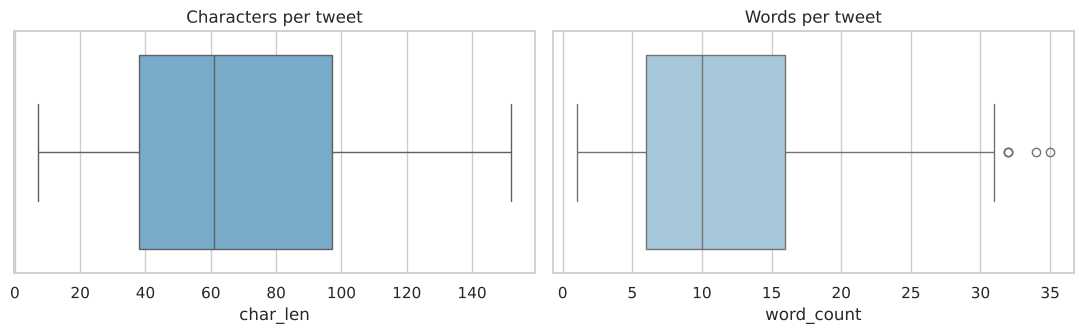

In [9]:
def iqr_outliers(x):
    q1, q3 = x.quantile([.25, .75]); i = q3 - q1
    return int(((x < q1 - 1.5*i) | (x > q3 + 1.5*i)).sum()), q1 - 1.5*i, q3 + 1.5*i

for c in ["char_len", "word_count"]:
    n, lo, hi = iqr_outliers(df[c])
    print(f"{c}: {n} IQR-outliers (fences {lo:.1f} – {hi:.1f}); min={df[c].min()}, max={df[c].max()}")
    R[f"outliers_{c}"] = n

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(x=df["char_len"], ax=ax[0], color="#6baed6"); ax[0].set_title("Characters per tweet")
sns.boxplot(x=df["word_count"], ax=ax[1], color="#9ecae1"); ax[1].set_title("Words per tweet")
savefig("01_outlier_boxplots")

**Decision:** tweets are length-limited by the platform, so the few "outliers" are valid long tweets, not errors. We **keep** them: they carry real text, and TF-IDF vectors are L2-normalised, which removes the effect of length on the models.

**Scaling / encoding summary.** *Encoding:* target mapped to 0/1; text converted to numbers via TF-IDF. *Scaling:* TF-IDF is already normalised; `StandardScaler` is applied only to the numeric metadata features in the metadata-only model (section 5.2).

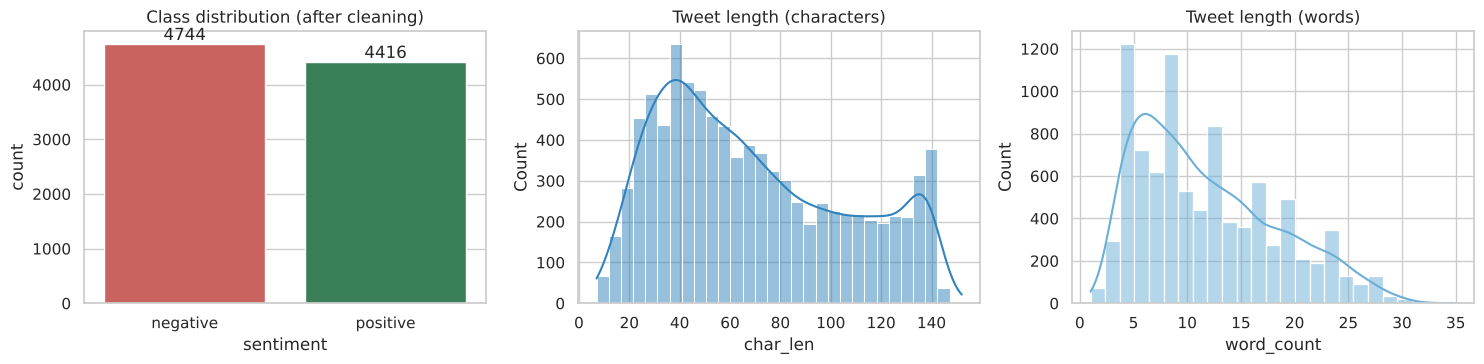

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.countplot(data=df, x="sentiment", order=["negative","positive"], palette=PALETTE, ax=ax[0])
ax[0].set_title("Class distribution (after cleaning)")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
sns.histplot(df["char_len"], bins=30, kde=True, ax=ax[1], color="#3182bd"); ax[1].set_title("Tweet length (characters)")
sns.histplot(df["word_count"], bins=25, kde=True, ax=ax[2], color="#6baed6"); ax[2].set_title("Tweet length (words)")
savefig("02_cleaning_overview")

## 4. Exploratory Data Analysis and Statistical Analysis

### 4.1 Univariate analysis

In [11]:
desc = df[NUM_COLS].describe().T
desc["skew"] = df[NUM_COLS].skew()
R["desc_stats"] = desc.round(3).to_dict(orient="index")
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,skew
char_len,9160.0,68.910,36.775,7.0,38.00,61.000,97.000,152.0,0.473
word_count,9160.0,11.819,6.492,1.0,6.00,10.000,16.000,35.0,0.674
n_hashtags,9160.0,0.226,0.906,0.0,0.00,0.000,0.000,10.0,5.840
n_mentions,9160.0,0.787,1.006,0.0,0.00,1.000,1.000,11.0,3.272
n_urls,9160.0,0.161,0.386,0.0,0.00,0.000,0.000,3.0,2.221
n_exclaim,9160.0,0.288,0.833,0.0,0.00,0.000,0.000,22.0,6.617
n_question,9160.0,0.123,0.424,0.0,0.00,0.000,0.000,7.0,4.818
upper_ratio,9160.0,0.097,0.131,0.0,0.03,0.065,0.121,1.0,4.047


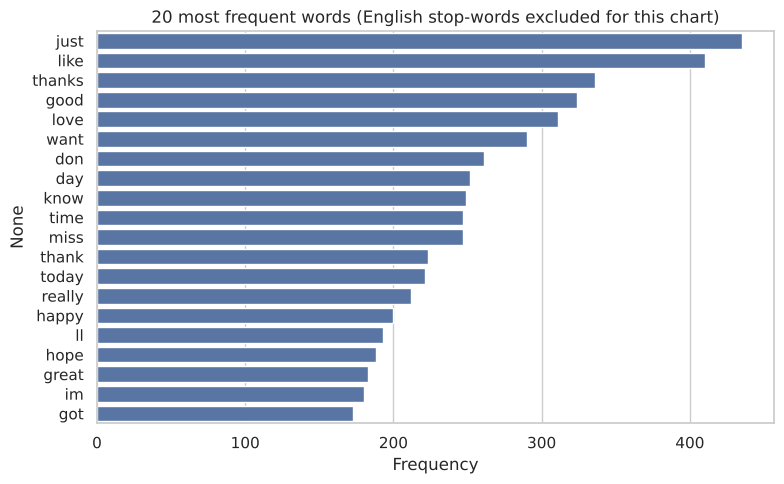

Vocabulary size (words appearing in >=3 tweets): 2516


In [12]:
cv_all = CountVectorizer(stop_words="english", min_df=3)
Xc = cv_all.fit_transform(df["clean_text"])
freq = pd.Series(np.asarray(Xc.sum(axis=0)).ravel(), index=cv_all.get_feature_names_out()).sort_values(ascending=False)
top = freq.head(20)
plt.figure(figsize=(8, 5))
sns.barplot(x=top.values, y=top.index, color="#4c72b0")
plt.title("20 most frequent words (English stop-words excluded for this chart)"); plt.xlabel("Frequency")
savefig("03_top_words_overall")
R["vocab_size_min_df3"] = int(len(freq))
R["top_words_overall"] = top.head(10).to_dict()
print("Vocabulary size (words appearing in >=3 tweets):", len(freq))

### 4.2 Bivariate analysis (feature vs. sentiment)

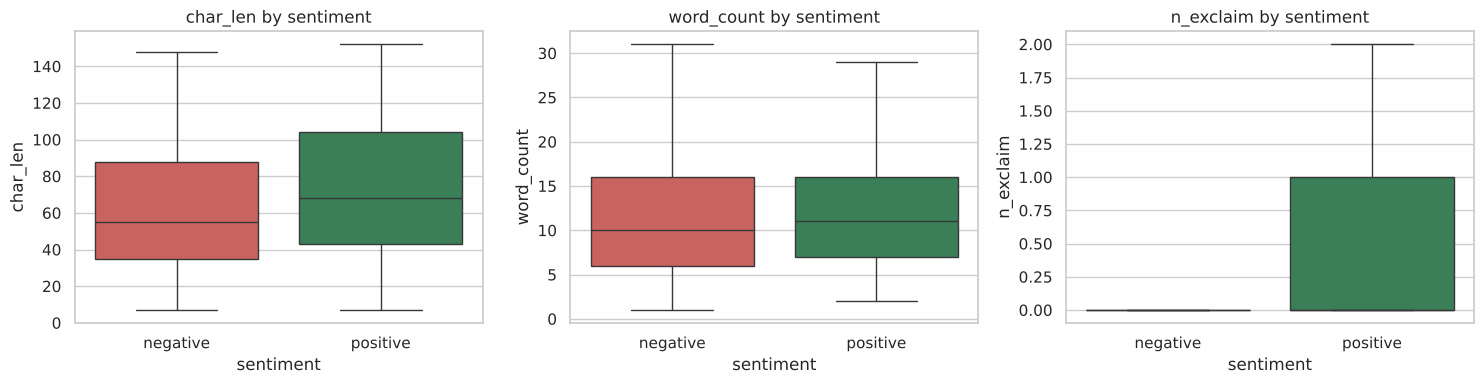

sentiment,negative,positive
char_len,63.867,74.327
word_count,11.514,12.146
n_hashtags,0.183,0.272
n_mentions,0.611,0.977
n_urls,0.113,0.213
n_exclaim,0.186,0.397
n_question,0.136,0.110
upper_ratio,0.092,0.104


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["char_len", "word_count", "n_exclaim"]):
    sns.boxplot(data=df, x="sentiment", y=c, order=["negative","positive"], palette=PALETTE, ax=a, showfliers=False)
    a.set_title(f"{c} by sentiment")
savefig("04_features_by_sentiment")

group_means = df.groupby("sentiment")[NUM_COLS].mean().T.round(3)
R["group_means"] = group_means.to_dict(orient="index")
group_means

In [14]:
# Hypothesis tests.  H0: the feature has the same distribution in positive and negative tweets.
rows = []
for c in ["char_len", "word_count", "n_exclaim", "n_question", "upper_ratio"]:
    a = df.loc[df.label == 1, c]; b = df.loc[df.label == 0, c]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r_rb = 1 - 2*u/(len(a)*len(b))            # rank-biserial effect size
    rows.append([c, a.median(), b.median(), u, p, r_rb])
mw = pd.DataFrame(rows, columns=["feature","median_pos","median_neg","U","p_value","rank_biserial"])
mw["significant(0.05)"] = mw["p_value"] < 0.05
R["mannwhitney"] = mw.round(6).to_dict(orient="records")
mw.round(5)

,feature,median_pos,median_neg,U,p_value,rank_biserial,significant(0.05)
0,char_len,68.00000,55.00000,12294848.0,0.00000,-0.17376,True
1,word_count,11.00000,10.00000,11276407.0,0.00000,-0.07653,True
2,n_exclaim,0.00000,0.00000,12051067.5,0.00000,-0.15049,True
3,n_question,0.00000,0.00000,10318262.0,0.01642,0.01494,True
4,upper_ratio,0.07895,0.05263,12689826.0,0.00000,-0.21147,True


In [15]:
# Chi-square test of independence for binary indicators vs sentiment + Wilson 95% CI of P(positive | indicator)
ind = {"has_hashtag": df.n_hashtags > 0, "has_mention": df.n_mentions > 0, "has_url": df.n_urls > 0,
       "has_exclaim": df.n_exclaim > 0, "has_question": df.n_question > 0}
rows = []
for name, mask in ind.items():
    ct = pd.crosstab(mask, df["label"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum(); v = np.sqrt(chi2 / n)                         # Cramer's V for 2x2
    k1, n1 = ct.loc[True, 1], ct.loc[True].sum()
    ci = stats.binomtest(int(k1), int(n1)).proportion_ci(method="wilson")
    rows.append([name, int(n1), k1/n1, ci.low, ci.high, chi2, p, v])
chi = pd.DataFrame(rows, columns=["indicator","n_with","P(pos|present)","CI_low","CI_high","chi2","p_value","cramers_V"])
R["chi2"] = chi.round(6).to_dict(orient="records")
chi.round(4)

,indicator,n_with,P(pos|present),CI_low,CI_high,chi2,p_value,cramers_V
0,has_hashtag,980,0.6480,0.6175,0.6772,120.1736,0.0000,0.1145
1,has_mention,5313,0.5535,0.5401,0.5669,257.9956,0.0000,0.1678
2,has_url,1414,0.6266,0.6011,0.6514,139.1435,0.0000,0.1232
3,has_exclaim,1620,0.6988,0.6760,0.7206,368.9888,0.0000,0.2007
4,has_question,899,0.4449,0.4128,0.4776,5.3484,0.0207,0.0242


In [16]:
# Interpretation printed automatically from the numbers above
print("INTERPRETATION")
for _, r in mw.iterrows():
    word = "differs" if r["p_value"] < 0.05 else "does not differ"
    print(f"- {r['feature']}: {word} between classes (Mann-Whitney p={r['p_value']:.4f}, effect size r={r['rank_biserial']:.3f}).")
for _, r in chi.iterrows():
    word = "is associated with" if r["p_value"] < 0.05 else "is NOT associated with"
    print(f"- {r['indicator']} {word} sentiment (chi2 p={r['p_value']:.4f}, Cramer's V={r['cramers_V']:.3f}); "
          f"P(positive | present)={r['P(pos|present)']:.3f} [95% CI {r['CI_low']:.3f}-{r['CI_high']:.3f}].")
print("\nNote: with ~10k rows even tiny differences can be 'significant'; always read the effect size.")

INTERPRETATION
- char_len: differs between classes (Mann-Whitney p=0.0000, effect size r=-0.174).
- word_count: differs between classes (Mann-Whitney p=0.0000, effect size r=-0.077).
- n_exclaim: differs between classes (Mann-Whitney p=0.0000, effect size r=-0.150).
- n_question: differs between classes (Mann-Whitney p=0.0164, effect size r=0.015).
- upper_ratio: differs between classes (Mann-Whitney p=0.0000, effect size r=-0.211).
- has_hashtag is associated with sentiment (chi2 p=0.0000, Cramer's V=0.115); P(positive | present)=0.648 [95% CI 0.618-0.677].
- has_mention is associated with sentiment (chi2 p=0.0000, Cramer's V=0.168); P(positive | present)=0.554 [95% CI 0.540-0.567].
- has_url is associated with sentiment (chi2 p=0.0000, Cramer's V=0.123); P(positive | present)=0.627 [95% CI 0.601-0.651].
- has_exclaim is associated with sentiment (chi2 p=0.0000, Cramer's V=0.201); P(positive | present)=0.699 [95% CI 0.676-0.721].
- has_question is associated with sentiment (chi2 p=0.0

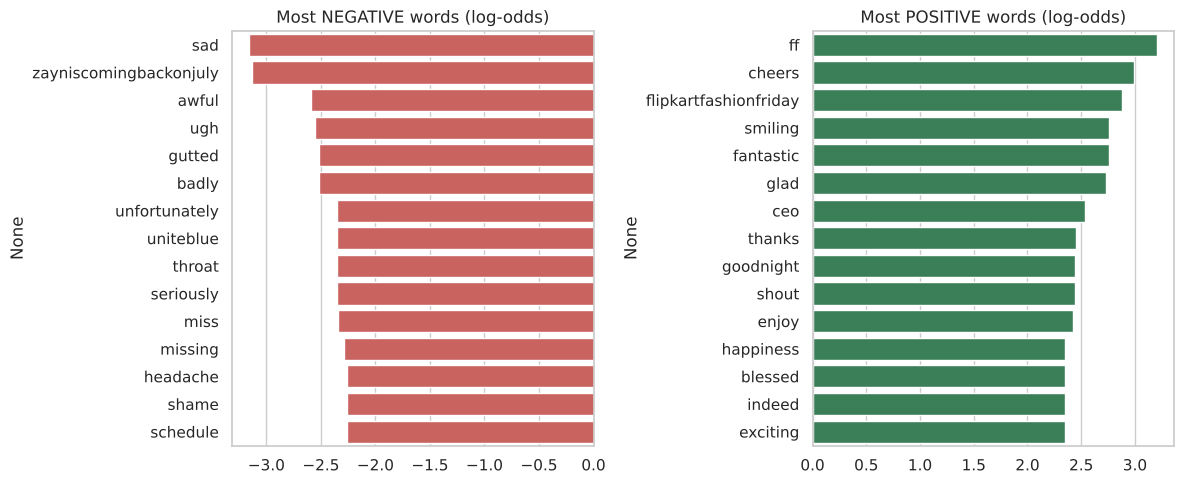

Negative: ['sad', 'zayniscomingbackonjuly', 'awful', 'ugh', 'gutted', 'badly', 'unfortunately', 'uniteblue', 'throat', 'seriously', 'miss', 'missing', 'headache', 'shame', 'schedule']
Positive: ['ff', 'cheers', 'flipkartfashionfriday', 'smiling', 'fantastic', 'glad', 'ceo', 'thanks', 'goodnight', 'shout', 'enjoy', 'happiness', 'blessed', 'indeed', 'exciting']


In [17]:
# Most discriminative words per class: smoothed log-odds ratio
cv2 = CountVectorizer(min_df=5)
Xw = cv2.fit_transform(df["clean_text"])
vocab = np.array(cv2.get_feature_names_out())
cp = np.asarray(Xw[df.label.values == 1].sum(axis=0)).ravel() + 1
cn = np.asarray(Xw[df.label.values == 0].sum(axis=0)).ravel() + 1
logodds = np.log(cp / cp.sum()) - np.log(cn / cn.sum())
order = np.argsort(logodds)
neg_words = pd.Series(logodds[order[:15]], index=vocab[order[:15]])
pos_words = pd.Series(logodds[order[-15:]][::-1], index=vocab[order[-15:]][::-1])

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(x=neg_words.values, y=neg_words.index, color=PALETTE["negative"], ax=ax[0]); ax[0].set_title("Most NEGATIVE words (log-odds)")
sns.barplot(x=pos_words.values, y=pos_words.index, color=PALETTE["positive"], ax=ax[1]); ax[1].set_title("Most POSITIVE words (log-odds)")
savefig("05_discriminative_words")
R["eda_neg_words"] = list(neg_words.index[:10]); R["eda_pos_words"] = list(pos_words.index[:10])
print("Negative:", list(neg_words.index)); print("Positive:", list(pos_words.index))

### 4.3 Multivariate analysis

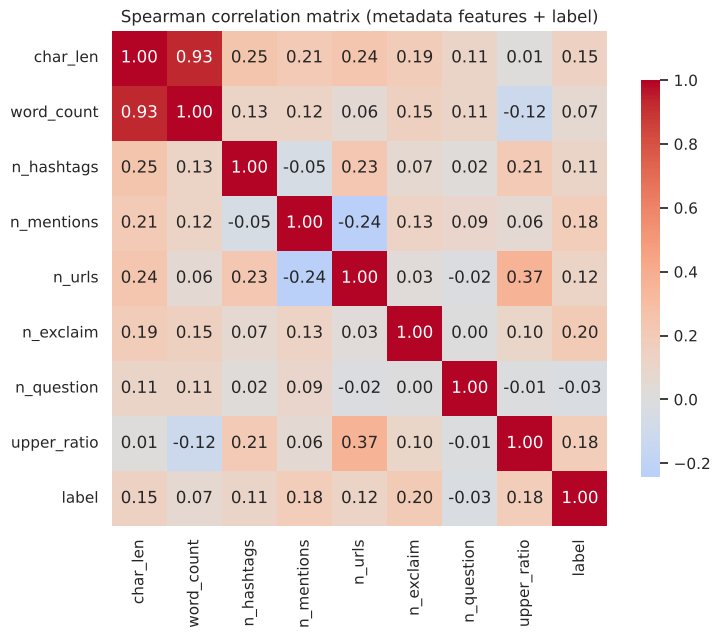

n_question    -0.025
word_count     0.066
n_hashtags     0.113
n_urls         0.125
char_len       0.150
upper_ratio    0.183
n_mentions     0.185
n_exclaim      0.196
Name: label, dtype: float64


In [18]:
corr = df[NUM_COLS + ["label"]].corr(method="spearman")
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Spearman correlation matrix (metadata features + label)")
savefig("06_correlation_heatmap")
R["corr_with_label"] = corr["label"].drop("label").round(3).to_dict()
print(corr["label"].drop("label").round(3).sort_values())

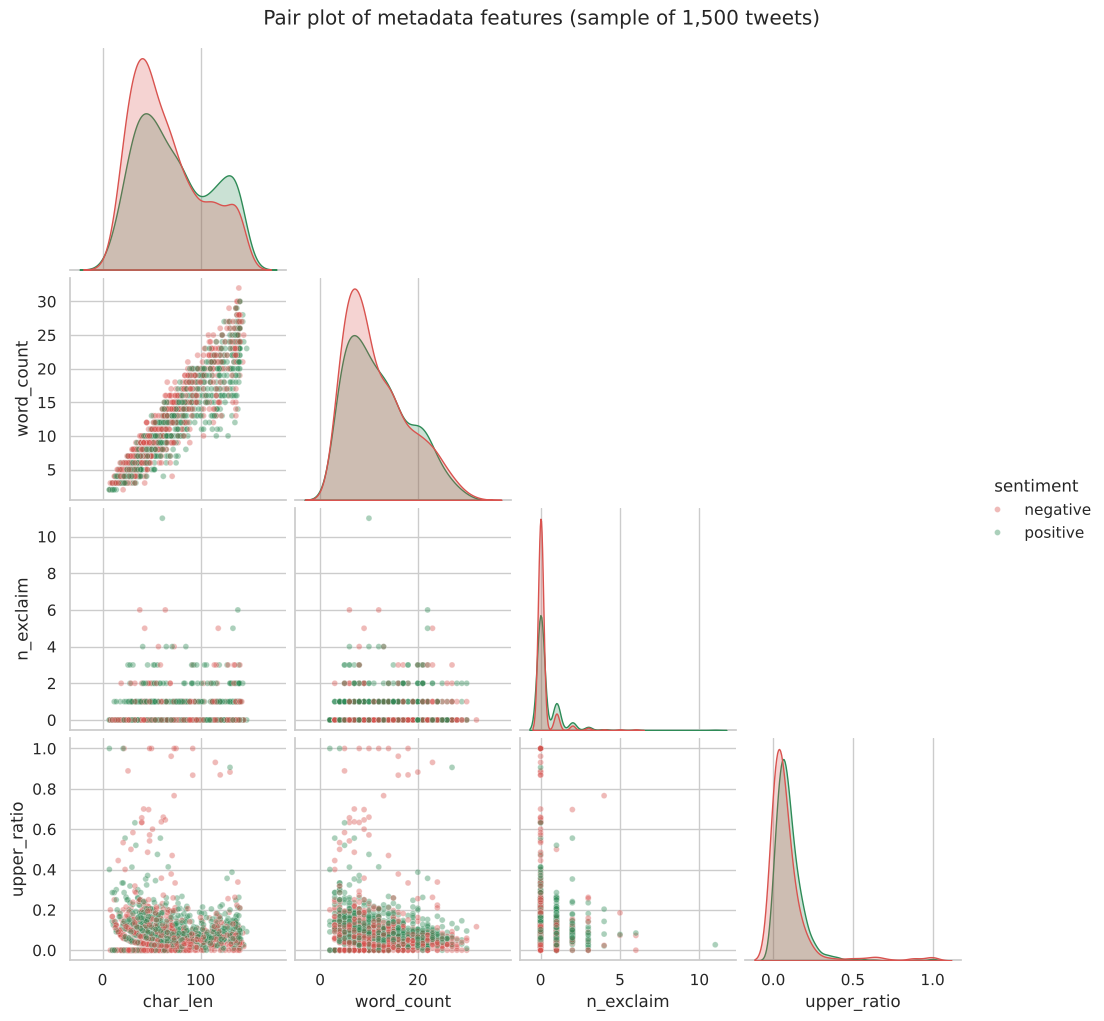

In [19]:
sample = df.sample(1500, random_state=SEED)
g = sns.pairplot(sample, vars=["char_len","word_count","n_exclaim","upper_ratio"], hue="sentiment",
                 palette=PALETTE, plot_kws={"alpha": .4, "s": 18}, corner=True)
g.fig.suptitle("Pair plot of metadata features (sample of 1,500 tweets)", y=1.02)
g.savefig("figures/07_pairplot.png", dpi=130, bbox_inches="tight"); plt.show()

**EDA take-aways (read together with the numbers printed above).**
- The classes are balanced, so accuracy and F1 will agree and no re-sampling is needed.
- Simple metadata (length, punctuation, capital letters) shows only **weak-to-modest relationships** with sentiment (|Spearman ρ| ≤ about 0.2 in the correlation matrix, small effect sizes), and a metadata-only model stays far below the text models (section 5.2). The *words themselves* are the main signal – which motivates a text model such as TF-IDF + classifier. Some metadata effects (e.g. @mentions) partly reflect how the tweets were collected rather than real sentiment.
- Highly discriminative words are intuitive (thanks / love / happy / follow vs. sad / miss / sorry / bad …), a good sanity check that the labels are meaningful even though they are noisy.

## 5. Model Development and Evaluation

### 5.1 Train / validation / test strategy
- **80 %** of the data is the *training set*, **20 %** is a *test set* that is never touched during tuning (stratified split, `random_state=42`).
- *Validation* = **5-fold stratified cross-validation** on the training set, used inside `GridSearchCV` to tune hyper-parameters and to choose the final model.
- Each model is a scikit-learn **`Pipeline`** (`TfidfVectorizer` → classifier). Because the vectoriser sits inside the pipeline, the vocabulary and IDF weights are re-learned only on the training part of each fold → **no data leakage**.

In [20]:
X = df["clean_text"]; y = df["label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
idx_train, idx_test = X_train.index, X_test.index
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("Train:", X_train.shape[0], "| Test:", X_test.shape[0])
print("Positive share  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))
R.update(n_train=int(len(X_train)), n_test=int(len(X_test)))

def get_scores(model, X_):
    return model.predict_proba(X_)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_)

def metrics_row(name, y_true, y_pred, y_score):
    return dict(model=name, accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred), f1=f1_score(y_true, y_pred),
                roc_auc=roc_auc_score(y_true, y_score))

test_rows = []; preds = {}; scores = {}

Train: 7328 | Test: 1832
Positive share  train: 0.482  test: 0.482


### 5.2 Baselines
1. **Dummy classifier** (always predicts the majority class) – the "do-nothing" floor.
2. **VADER** – a *pretrained* rule-based sentiment lexicon (Hutto & Gilbert, 2014) that needs no training. It is applied to text with the same leak sources removed.
3. **Metadata-only logistic regression** (scaled numeric features) – shows how much sentiment can be guessed without understanding words.

In [21]:
# 1) Dummy
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
p = dummy.predict(X_test); s = dummy.predict_proba(X_test)[:, 1]
test_rows.append(metrics_row("Baseline: Majority class", y_test, p, s)); preds["Majority class"] = p; scores["Majority class"] = s

# 2) VADER (pretrained, no training)
sia = SentimentIntensityAnalyzer()
vs = df.loc[idx_test, "vader_text"].apply(lambda t: sia.polarity_scores(t)["compound"]).values
pv = (vs > 0).astype(int)
test_rows.append(metrics_row("Pretrained: VADER lexicon", y_test, pv, vs)); preds["VADER"] = pv; scores["VADER"] = vs

# 3) Metadata-only logistic regression (uses StandardScaler)
meta = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=1000, random_state=SEED))])
meta.fit(df.loc[idx_train, NUM_COLS], y_train)
pm = meta.predict(df.loc[idx_test, NUM_COLS]); sm = meta.predict_proba(df.loc[idx_test, NUM_COLS])[:, 1]
test_rows.append(metrics_row("Baseline: Metadata-only LR", y_test, pm, sm)); preds["Metadata LR"] = pm; scores["Metadata LR"] = sm

pd.DataFrame(test_rows).round(4)

,model,accuracy,precision,recall,f1,roc_auc
0,Baseline: Majority class,0.5180,0.0000,0.0000,0.0000,0.5000
1,Pretrained: VADER lexicon,0.6512,0.6556,0.5821,0.6167,0.7193
2,Baseline: Metadata-only LR,0.6425,0.6629,0.5255,0.5862,0.6903


### 5.3 TF-IDF + machine-learning models with hyper-parameter tuning
Four classifiers on TF-IDF features (sub-linear term frequency, `min_df=2`, uni-grams vs. uni+bi-grams tuned):
| Model | Why it is a good candidate | Tuned |
|---|---|---|
| Logistic Regression | strong, interpretable text baseline | `C`, n-gram range |
| Linear SVM | margin-based, excellent in high-dimensional sparse spaces | `C`, n-gram range |
| Multinomial Naive Bayes | fast probabilistic model for word counts | `alpha`, n-gram range |
| Random Forest | non-linear ensemble for comparison | `max_depth`, n-gram range |

Scoring metric for tuning: **F1-score** (5-fold CV).

In [22]:
def make_pipe(clf):
    return Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True, min_df=2, strip_accents="unicode")), ("clf", clf)])

NG = {"tfidf__ngram_range": [(1, 1), (1, 2)]}
candidates = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=SEED), {**NG, "clf__C": [0.1, 1, 10]}),
    "Linear SVM":          (LinearSVC(random_state=SEED),                          {**NG, "clf__C": [0.05, 0.1, 0.5, 1]}),
    "Multinomial NB":      (MultinomialNB(),                                       {**NG, "clf__alpha": [0.1, 0.5, 1.0]}),
    "Random Forest":       (RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
                            {**NG, "clf__max_depth": [None, 50]}),
}

fitted, cv_rows = {}, []
for name, (clf, grid) in candidates.items():
    t0 = time.time()
    gs = GridSearchCV(make_pipe(clf), grid, scoring="f1", cv=cv, n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    fit_time = time.time() - t0
    best = gs.best_estimator_; fitted[name] = best
    k = gs.best_index_
    cv_rows.append(dict(model=name, cv_f1_mean=gs.cv_results_["mean_test_score"][k],
                        cv_f1_std=gs.cv_results_["std_test_score"][k],
                        best_params=str({a.split("__")[1]: b for a, b in gs.best_params_.items()}),
                        tuning_seconds=round(fit_time, 1)))
    p = best.predict(X_test); s = get_scores(best, X_test)
    test_rows.append(metrics_row(name, y_test, p, s)); preds[name] = p; scores[name] = s
    print(f"{name:20s} best CV F1 = {gs.best_score_:.4f}  params = {gs.best_params_}  ({fit_time:.0f}s)")

cv_table = pd.DataFrame(cv_rows).sort_values("cv_f1_mean", ascending=False).reset_index(drop=True)
cv_table.round(4)

Logistic Regression  best CV F1 = 0.7302  params = {'clf__C': 1, 'tfidf__ngram_range': (1, 2)}  (3s)


Linear SVM           best CV F1 = 0.7289  params = {'clf__C': 0.1, 'tfidf__ngram_range': (1, 2)}  (4s)


Multinomial NB       best CV F1 = 0.7251  params = {'clf__alpha': 1.0, 'tfidf__ngram_range': (1, 2)}  (3s)


Random Forest        best CV F1 = 0.7055  params = {'clf__max_depth': None, 'tfidf__ngram_range': (1, 1)}  (128s)


,model,cv_f1_mean,cv_f1_std,best_params,tuning_seconds
0,Logistic Regression,0.7302,0.0188,"{'C': 1, 'ngram_range': (1, 2)}",3.1
1,Linear SVM,0.7289,0.0194,"{'C': 0.1, 'ngram_range': (1, 2)}",3.9
2,Multinomial NB,0.7251,0.0136,"{'alpha': 1.0, 'ngram_range': (1, 2)}",2.8
3,Random Forest,0.7055,0.0171,"{'max_depth': None, 'ngram_range': (1, 1)}",127.9


### 5.4 Model comparison on the untouched test set

In [23]:
results = pd.DataFrame(test_rows).set_index("model")
results_sorted = results.sort_values("f1", ascending=False)
results_sorted.round(4).to_csv("results/test_metrics.csv")
cv_table.round(4).to_csv("results/cv_results.csv", index=False)
R["test_metrics"] = results.round(4).to_dict(orient="index")
R["cv_table"] = cv_table.round(4).to_dict(orient="records")
results_sorted.round(4)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Linear SVM,0.7642,0.7801,0.7112,0.7441,0.8451
Logistic Regression,0.7631,0.7775,0.7123,0.7435,0.8453
Multinomial NB,0.7609,0.7924,0.6829,0.7336,0.8451
Random Forest,0.7222,0.7320,0.6682,0.6986,0.7961
Pretrained: VADER lexicon,0.6512,0.6556,0.5821,0.6167,0.7193
Baseline: Metadata-only LR,0.6425,0.6629,0.5255,0.5862,0.6903
Baseline: Majority class,0.5180,0.0000,0.0000,0.0000,0.5000


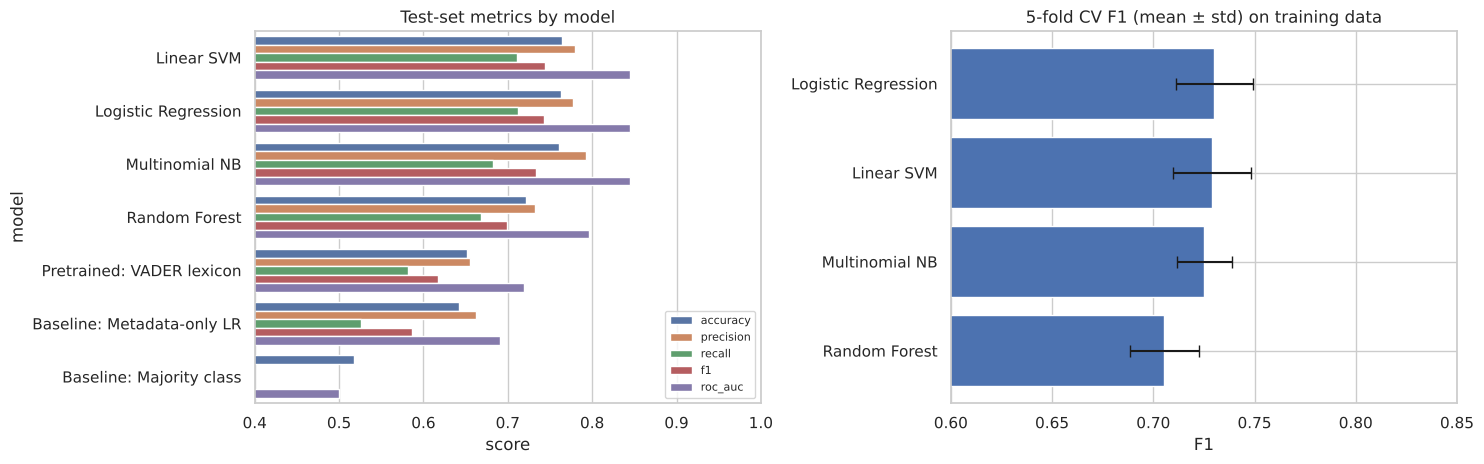

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
plot_df = results_sorted[["accuracy","precision","recall","f1","roc_auc"]].reset_index().melt(id_vars="model", var_name="metric", value_name="score")
sns.barplot(data=plot_df, y="model", x="score", hue="metric", ax=ax[0])
ax[0].set_xlim(0.4, 1.0); ax[0].set_title("Test-set metrics by model"); ax[0].legend(loc="lower right", fontsize=8)

cvp = cv_table.sort_values("cv_f1_mean")
ax[1].barh(cvp["model"], cvp["cv_f1_mean"], xerr=cvp["cv_f1_std"], color="#4c72b0", capsize=4)
ax[1].set_xlim(0.6, 0.85); ax[1].set_title("5-fold CV F1 (mean ± std) on training data"); ax[1].set_xlabel("F1")
savefig("08_model_comparison")

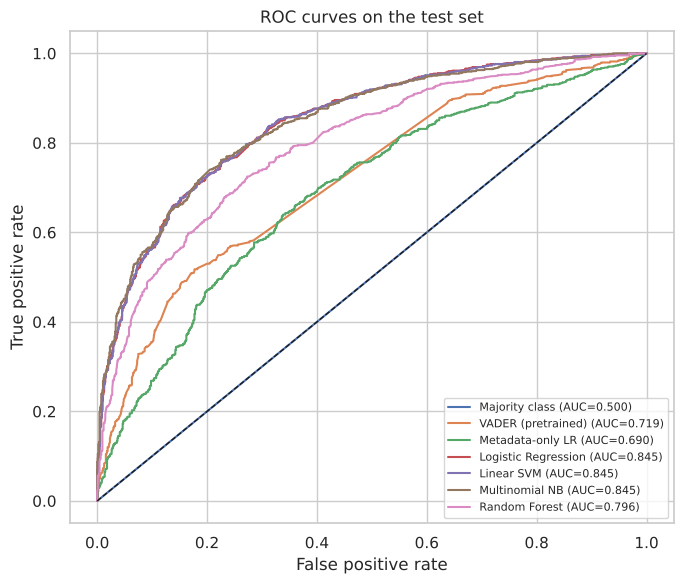

In [25]:
# ROC curves
plt.figure(figsize=(7, 6))
labels = {"Majority class":"Majority class", "VADER":"VADER (pretrained)", "Metadata LR":"Metadata-only LR",
          **{k: k for k in candidates}}
for k, s in scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    plt.plot(fpr, tpr, label=f"{labels[k]} (AUC={roc_auc_score(y_test, s):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves on the test set"); plt.legend(fontsize=8)
savefig("09_roc_curves")

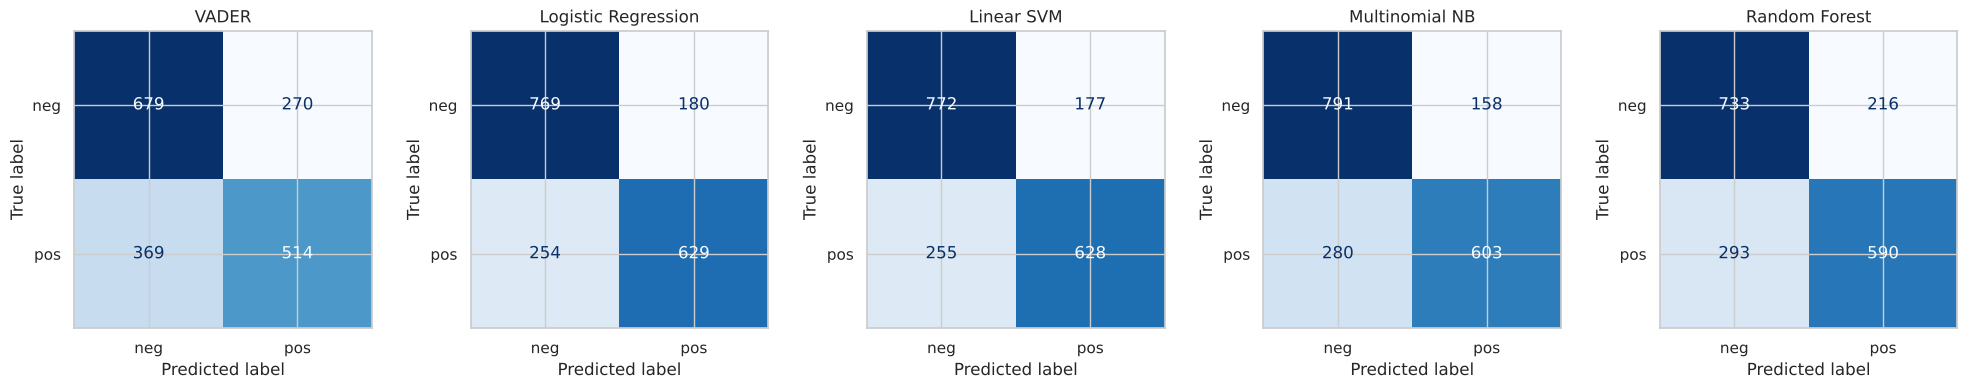

In [26]:
# Confusion matrices
show = ["VADER", "Logistic Regression", "Linear SVM", "Multinomial NB", "Random Forest"]
fig, axes = plt.subplots(1, len(show), figsize=(4*len(show), 3.8))
for a, k in zip(axes, show):
    cm = confusion_matrix(y_test, preds[k])
    ConfusionMatrixDisplay(cm, display_labels=["neg", "pos"]).plot(ax=a, cmap="Blues", colorbar=False, values_format="d")
    a.set_title(k)
savefig("10_confusion_matrices")

### 5.5 Choosing the final model

In [27]:
# Final model is chosen using CROSS-VALIDATION only (never the test set).
final_name = cv_table.loc[0, "model"]
final_model = fitted[final_name]
print("Final model (highest CV F1):", final_name)
print("Parameters:", cv_table.loc[0, "best_params"])
print()
print(classification_report(y_test, preds[final_name], target_names=["negative", "positive"], digits=3))
R["final_model"] = final_name
R["final_params"] = cv_table.loc[0, "best_params"]
R["final_test"] = results.loc[final_name].round(4).to_dict()
R["class_report"] = classification_report(y_test, preds[final_name], target_names=["negative","positive"], output_dict=True)

# success criteria check
f = results.loc[final_name]
crit = {"F1 >= 0.70": bool(f.f1 >= 0.70), "ROC-AUC >= 0.75": bool(f.roc_auc >= 0.75),
        "beats Majority baseline (F1)": bool(f.f1 > results.loc["Baseline: Majority class", "f1"]),
        "beats VADER (F1)": bool(f.f1 > results.loc["Pretrained: VADER lexicon", "f1"])}
R["criteria"] = crit
print("Success criteria:", crit)

Final model (highest CV F1): Logistic Regression
Parameters: {'C': 1, 'ngram_range': (1, 2)}

              precision    recall  f1-score   support

    negative      0.752     0.810     0.780       949
    positive      0.778     0.712     0.743       883

    accuracy                          0.763      1832
   macro avg      0.765     0.761     0.762      1832
weighted avg      0.764     0.763     0.762      1832

Success criteria: {'F1 >= 0.70': True, 'ROC-AUC >= 0.75': True, 'beats Majority baseline (F1)': True, 'beats VADER (F1)': True}


### 5.6 Statistical confidence in the results

In [28]:
# (a) Bootstrap 95% confidence interval for accuracy and F1 of the final model
rng = np.random.default_rng(SEED)
yt = y_test.values; yp = preds[final_name]
accs, f1s = [], []
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    accs.append(accuracy_score(yt[i], yp[i])); f1s.append(f1_score(yt[i], yp[i]))
ci_acc = np.percentile(accs, [2.5, 97.5]); ci_f1 = np.percentile(f1s, [2.5, 97.5])
print(f"Accuracy 95% CI: {ci_acc[0]:.3f} - {ci_acc[1]:.3f}")
print(f"F1       95% CI: {ci_f1[0]:.3f} - {ci_f1[1]:.3f}")
R["ci_acc"] = ci_acc.round(4).tolist(); R["ci_f1"] = ci_f1.round(4).tolist()

# (b) McNemar exact test: final model vs. each other ML model (are the differences real?)
mc_rows = []
for other in candidates:
    if other == final_name: continue
    a = (preds[final_name] == yt); b = (preds[other] == yt)
    n01 = int(((a) & (~b)).sum()); n10 = int(((~a) & (b)).sum())
    p = stats.binomtest(n01, n01 + n10, 0.5).pvalue if (n01 + n10) > 0 else 1.0
    mc_rows.append([f"{final_name} vs {other}", n01, n10, p])
mcn = pd.DataFrame(mc_rows, columns=["comparison","final_right_other_wrong","other_right_final_wrong","p_value"])
R["mcnemar"] = mcn.round(5).to_dict(orient="records")
mcn.round(5)

Accuracy 95% CI: 0.744 - 0.782
F1       95% CI: 0.719 - 0.766


,comparison,final_right_other_wrong,other_right_final_wrong,p_value
0,Logistic Regression vs Linear SVM,5,7,0.77441
1,Logistic Regression vs Multinomial NB,87,83,0.81811
2,Logistic Regression vs Random Forest,162,87,0.00000


**How to read it:** the bootstrap interval shows how much the test score could move if we had drawn a different test sample. McNemar's test asks whether two models' *errors* differ more than chance would explain; a large p-value means the models are statistically **indistinguishable** on this test set, so choosing between them can rely on simplicity/speed/interpretability.

### 5.7 Model interpretation – which words drive the prediction?

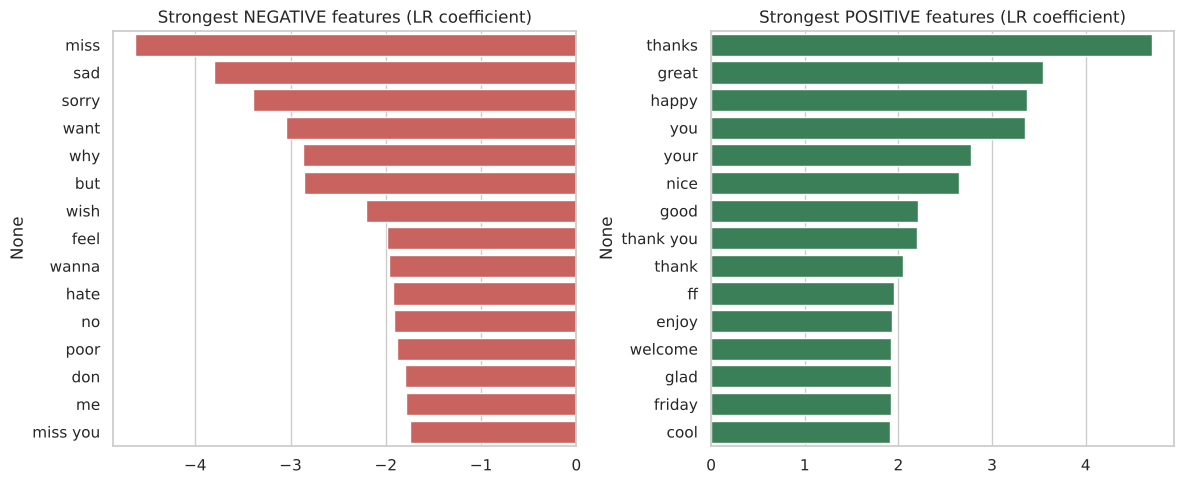

Negative: ['miss', 'sad', 'sorry', 'want', 'why', 'but', 'wish', 'feel', 'wanna', 'hate', 'no', 'poor', 'don', 'me', 'miss you']
Positive: ['thanks', 'great', 'happy', 'you', 'your', 'nice', 'good', 'thank you', 'thank', 'ff', 'enjoy', 'welcome', 'glad', 'friday', 'cool']


In [29]:
lr_pipe = fitted["Logistic Regression"]
names = np.array(lr_pipe.named_steps["tfidf"].get_feature_names_out())
coef = lr_pipe.named_steps["clf"].coef_.ravel()
o = np.argsort(coef)
neg_top = pd.Series(coef[o[:15]], index=names[o[:15]]); pos_top = pd.Series(coef[o[-15:]][::-1], index=names[o[-15:]][::-1])

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(x=neg_top.values, y=neg_top.index, color=PALETTE["negative"], ax=ax[0]); ax[0].set_title("Strongest NEGATIVE features (LR coefficient)")
sns.barplot(x=pos_top.values, y=pos_top.index, color=PALETTE["positive"], ax=ax[1]); ax[1].set_title("Strongest POSITIVE features (LR coefficient)")
savefig("11_feature_importance")
R["lr_neg_features"] = list(neg_top.index[:10]); R["lr_pos_features"] = list(pos_top.index[:10])
print("Negative:", list(neg_top.index)); print("Positive:", list(pos_top.index))

### 5.8 Error analysis, length effect and learning curve

In [30]:
err = df.loc[idx_test].copy()
err["pred"] = preds[final_name]
wrong = err[err.pred != err.label]
print(f"Misclassified: {len(wrong)} of {len(err)} ({len(wrong)/len(err):.1%})")
print("False positives (true neg, predicted pos):", int(((wrong.label == 0)).sum()),
      "| False negatives (true pos, predicted neg):", int(((wrong.label == 1)).sum()))
R["n_wrong"] = int(len(wrong)); R["fp"] = int((wrong.label == 0).sum()); R["fn"] = int((wrong.label == 1).sum())
pd.set_option("display.max_colwidth", 130)
wrong[["text", "sentiment", "pred"]].head(10).assign(pred=lambda d: d.pred.map({0:"negative",1:"positive"}))

Misclassified: 434 of 1832 (23.7%)
False positives (true neg, predicted pos): 180 | False negatives (true pos, predicted neg): 254


,text,sentiment,pred
7456,@blairforce2 which means its on its way over here :( 3rd load just hung up,negative,positive
3614,@JannikMarioFan Pech! :D,positive,negative
1078,@spaqhetto @ArtOfBsing Little finger is in this too??!! :D,positive,negative
1133,Low priority match :) hahaha,positive,negative
6066,@photopitchicks do u have instagram? So that I can tag you :),positive,negative
8541,@melfoster666 That's not true.\nI can quit whenever I want to.\n:D,positive,negative
917,@vipervillan haaa you would miss him :-),positive,negative
5777,getting home at 4 waking up at 9 :):),positive,negative
4651,@PureBexcellence Don't do that. :( I'll try to catch you if you do.,negative,positive
3424,"“@RobinhoodApp: We love spotting Robinhood out in the wild! Thanks for all the support out there, Robinhoodies! 🚙💚 http://t.co...",negative,positive


len_bucket
(1.999, 6.0]    0.735
(6.0, 10.0]     0.773
(10.0, 16.0]    0.772
(16.0, 32.0]    0.773
Name: correct, dtype: float64


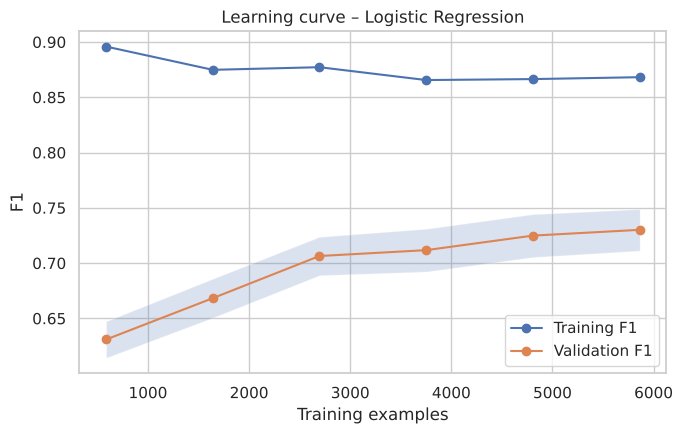

In [31]:
err["correct"] = (err.pred == err.label)
err["len_bucket"] = pd.qcut(err["word_count"], 4, duplicates="drop")
by_len = err.groupby("len_bucket")["correct"].mean()
print(by_len.round(3))
R["acc_by_len"] = {str(k): round(float(v), 4) for k, v in by_len.items()}

sizes, tr, va = learning_curve(final_model, X_train, y_train, cv=cv, scoring="f1",
                               train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, random_state=SEED)
plt.figure(figsize=(7, 4.5))
plt.plot(sizes, tr.mean(1), "o-", label="Training F1"); plt.plot(sizes, va.mean(1), "o-", label="Validation F1")
plt.fill_between(sizes, va.mean(1)-va.std(1), va.mean(1)+va.std(1), alpha=.2)
plt.xlabel("Training examples"); plt.ylabel("F1"); plt.title(f"Learning curve – {final_name}"); plt.legend()
savefig("12_learning_curve")
R["learning_curve"] = dict(sizes=sizes.tolist(), train=tr.mean(1).round(4).tolist(), val=va.mean(1).round(4).tolist())

## 6. Save the final model and make predictions

In [32]:
joblib.dump(final_model, "models/sentiment_model.joblib")
print("Saved -> models/sentiment_model.joblib")

def predict_sentiment(texts):
    if isinstance(texts, str): texts = [texts]
    cleaned = [clean_text(t) for t in texts]
    model = joblib.load("models/sentiment_model.joblib")
    labels = model.predict(cleaned)
    s = get_scores(model, cleaned)
    return pd.DataFrame({"text": texts, "prediction": np.where(labels == 1, "positive", "negative"), "score": np.round(s, 3)})

demo = ["I absolutely love this phone, the battery life is amazing!",
        "Worst delivery ever. Package arrived broken and nobody replied to my emails.",
        "Thanks so much for the quick help, really appreciate it",
        "I am so sad and tired today, nothing is going right",
        "This is not good at all"]
demo_out = predict_sentiment(demo)
R["demo"] = demo_out.to_dict(orient="records")
demo_out

Saved -> models/sentiment_model.joblib


,text,prediction,score
0,"I absolutely love this phone, the battery life is amazing!",positive,0.742
1,Worst delivery ever. Package arrived broken and nobody replied to my emails.,negative,0.324
2,"Thanks so much for the quick help, really appreciate it",positive,0.749
3,"I am so sad and tired today, nothing is going right",negative,0.064
4,This is not good at all,negative,0.358


## 7. Conclusion, Limitations and Future Work
Results, interpretation and limitations are written up in the accompanying report (`report/Sentiment_Analysis_Report.docx`). The key limitations are:
- **Noisy, emoticon-derived labels** – some "positive" tweets are sarcastic or neutral; the real ceiling for this dataset is below 100 %.
- **Only two classes**, English only, one platform and one time period → limited generalisation.
- **Bag-of-words** ignores word order beyond bi-grams, so sarcasm, negation scope and context are hard.
- **Possible improvements:** a larger human-labelled dataset (e.g. Amazon/Flipkart product reviews), fine-tuning a transformer such as DistilBERT/RoBERTa, handling negation and emojis explicitly, a neutral class, and probability calibration.

In [33]:
with open("results/summary.json", "w") as fh:
    json.dump(R, fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("All results saved. Keys:", list(R.keys()))

All results saved. Keys: ['n_records_raw', 'n_missing', 'class_counts_raw', 'dup_raw', 'emoticon_share', 'n_empty', 'n_conflict', 'n_neardup', 'n_records_clean', 'class_counts_clean', 'outliers_char_len', 'outliers_word_count', 'desc_stats', 'vocab_size_min_df3', 'top_words_overall', 'group_means', 'mannwhitney', 'chi2', 'eda_neg_words', 'eda_pos_words', 'corr_with_label', 'n_train', 'n_test', 'test_metrics', 'cv_table', 'final_model', 'final_params', 'final_test', 'class_report', 'criteria', 'ci_acc', 'ci_f1', 'mcnemar', 'lr_neg_features', 'lr_pos_features', 'n_wrong', 'fp', 'fn', 'acc_by_len', 'learning_curve', 'demo']
